# Animal classification CNN - PyTorch

Dataset: 15 animal classes, one folder per class. ImageFolder sorts folders lexicographically; this exact order is used for labels, output units, and animals_meta.json. The CNN receives RGB pixels in [0,1]. EfficientNetB0 receives the same pixels and applies ImageNet normalization exactly once inside the model, in training and prediction.

The split is stratified 80/20. Final models are exported only when validation accuracy is clearly above chance; checkpoints are selected by validation accuracy.

## 1. Configuración y librerías

In [ ]:
# Instalación de paquetes necesarios
!pip -q install kaggle torch torchvision scikit-learn matplotlib seaborn pandas Pillow

In [ ]:
import os, random, glob, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, Subset
from torch.optim.lr_scheduler import ReduceLROnPlateau
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import balanced_accuracy_score, f1_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Dispositivo:', device)

plt.style.use('seaborn-v0_8')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 10

Dispositivo: cpu


## 2. Carga del dataset

In [ ]:
import zipfile

zip_file = 'archive.zip'
extract_dir = '/content/data'

if os.path.exists(zip_file):
    print(f"Descomprimiendo '{zip_file}'...")
    os.makedirs(extract_dir, exist_ok=True)
    with zipfile.ZipFile(zip_file, 'r') as z:
        z.extractall(extract_dir)
    print("Listo.")
else:
    print(f"'{zip_file}' no encontrado. Asegúrate de subirlo a Colab.")

Descomprimiendo 'archive.zip'...
Listo.


In [ ]:
DATA_ROOT = '/content/data/animal_data'
if not os.path.isdir(DATA_ROOT):
    raise FileNotFoundError(f'No existe DATA_ROOT={DATA_ROOT}. Extrae el dataset y ajusta esta ruta.')

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
transform_train = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),  # RGB uint8 [0,255] -> float32 CHW [0,1]
])
transform_val = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
])

# ImageFolder fija un orden lexicografico de clases; se reutiliza sin mutar datasets compartidos.
base_dataset = datasets.ImageFolder(DATA_ROOT)
classes = base_dataset.classes
NUM_CLASSES = len(classes)
if NUM_CLASSES != 15:
    raise ValueError(f'Se esperaban 15 clases, se encontraron {NUM_CLASSES}: {classes}')
all_targets = np.asarray([label for _, label in base_dataset.samples], dtype=np.int64)
indices = np.arange(len(all_targets))
train_indices, val_indices = train_test_split(
    indices, test_size=0.2, random_state=SEED, stratify=all_targets
)

train_base = datasets.ImageFolder(DATA_ROOT, transform=transform_train)
val_base = datasets.ImageFolder(DATA_ROOT, transform=transform_val)
if train_base.classes != classes or val_base.classes != classes:
    raise ValueError('ImageFolder produjo ordenes de clase distintos entre train y validacion.')
train_set = Subset(train_base, train_indices.tolist())
val_set = Subset(val_base, val_indices.tolist())

BATCH_SIZE = 32
loader_options = {'num_workers': 0, 'pin_memory': device.type == 'cuda'}
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, **loader_options)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, **loader_options)
print(f'Orden exacto de clases/salidas ({NUM_CLASSES}):', classes)
print(f'Train: {len(train_set)} | Validacion: {len(val_set)}')

sample_images, sample_labels = next(iter(train_loader))
assert sample_images.shape[1:] == (3, 128, 128)
assert sample_images.dtype == torch.float32
assert int(sample_labels.min()) >= 0 and int(sample_labels.max()) < NUM_CLASSES
assert float(sample_images.min()) >= 0.0 and float(sample_images.max()) <= 1.0
print('Entrada RGB:', tuple(sample_images.shape), sample_images.dtype,
      'rango', float(sample_images.min()), float(sample_images.max()),
      '| etiquetas:', tuple(sample_labels.shape), 'rango',
      int(sample_labels.min()), int(sample_labels.max()))

Orden exacto de clases/salidas (15): ['Bear', 'Bird', 'Cat', 'Cow', 'Deer', 'Dog', 'Dolphin', 'Elephant', 'Giraffe', 'Horse', 'Kangaroo', 'Lion', 'Panda', 'Tiger', 'Zebra']
Train: 1555 | Validacion: 389
Entrada RGB: (32, 3, 128, 128) torch.float32 rango 0.0 1.0 | etiquetas: (32,) rango 1 14


## 3. Exploración rápida

In [ ]:
# Recuento de imágenes por clase
print("Imágenes por clase:")
for cls in sorted(os.listdir(DATA_ROOT)):
    cls_path = os.path.join(DATA_ROOT, cls)
    if os.path.isdir(cls_path):
        n = len([f for f in os.listdir(cls_path) if f.lower().endswith(('.jpg','.jpeg','.png'))])
        print(f"  {cls}: {n}")

Imágenes por clase:
  Bear: 125
  Bird: 137
  Cat: 123
  Cow: 131
  Deer: 127
  Dog: 122
  Dolphin: 129
  Elephant: 133
  Giraffe: 129
  Horse: 130
  Kangaroo: 126
  Lion: 131
  Panda: 135
  Tiger: 129
  Zebra: 137


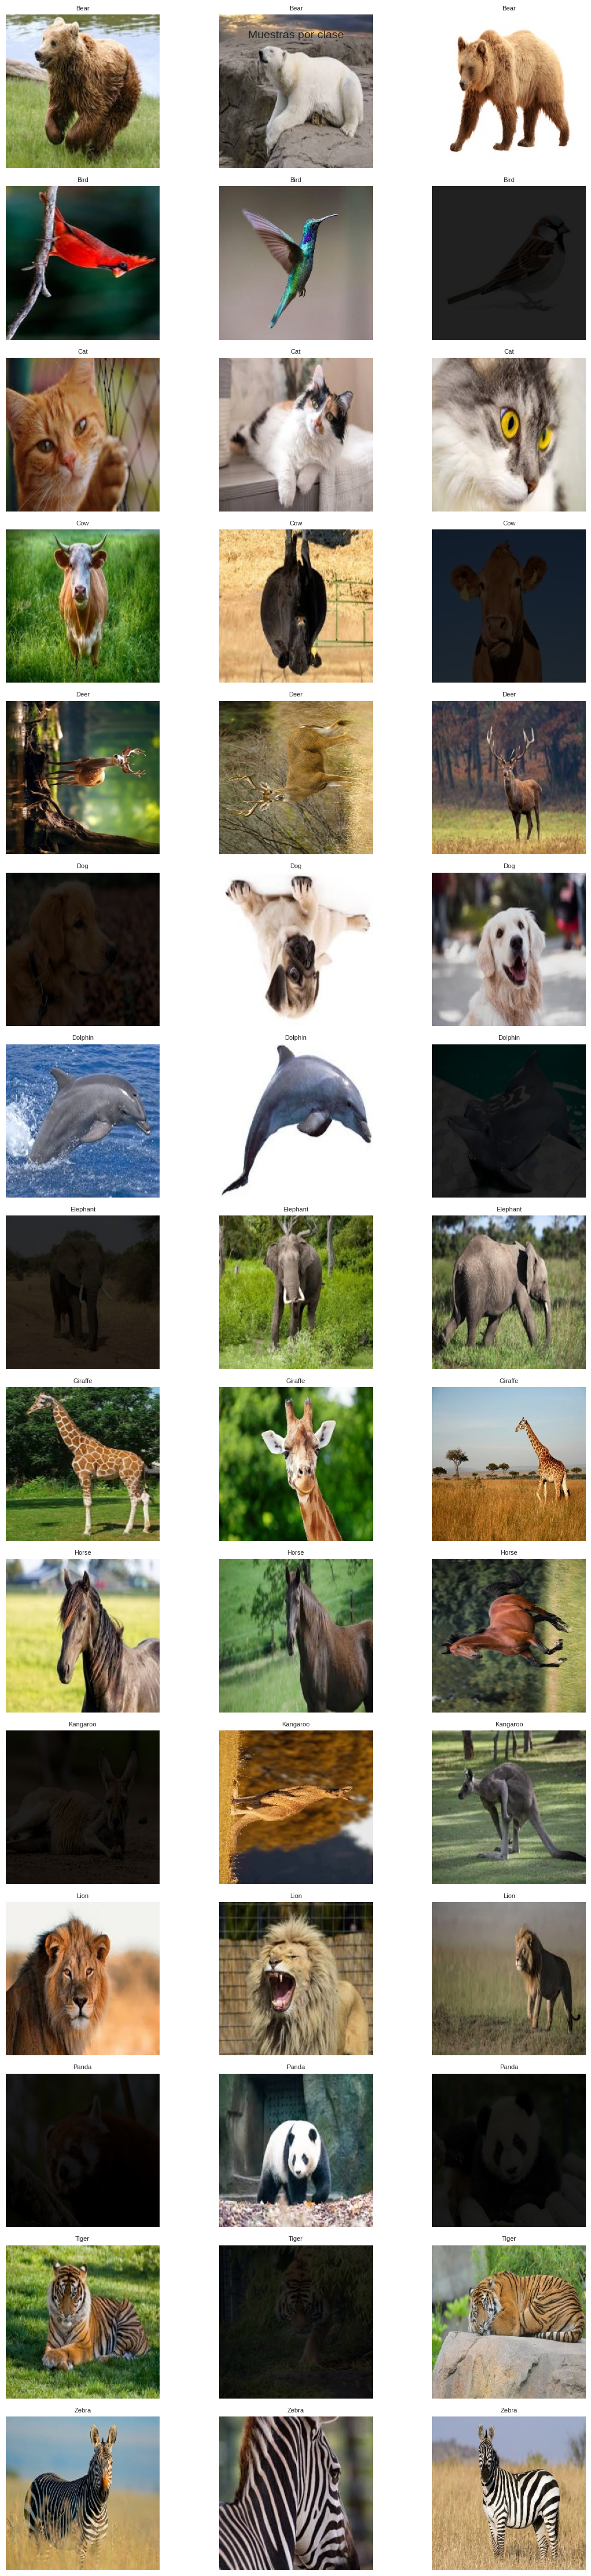

In [ ]:
# Muestra 3 imágenes de cada clase
def show_samples_by_class(root, n_per_class=3):
    cls_list = sorted([d for d in os.listdir(root) if os.path.isdir(os.path.join(root, d))])
    cols = n_per_class
    rows = len(cls_list)
    fig, axes = plt.subplots(rows, cols, figsize=(4*cols, 3*rows))
    for r, cls in enumerate(cls_list):
        imgs = glob.glob(os.path.join(root, cls, '*'))
        random.shuffle(imgs)
        for c in range(cols):
            ax = axes[r][c]
            if c < len(imgs):
                ax.imshow(Image.open(imgs[c]))
                ax.axis('off')
                ax.set_title(cls, fontsize=8)
            else:
                ax.axis('off')
    fig.suptitle('Muestras por clase', fontsize=14)
    plt.tight_layout()
    plt.show()

show_samples_by_class(DATA_ROOT, n_per_class=3)

## 4. Modelos
### 4.1 CNN desde cero (Baseline)
Misma arquitectura que el notebook base del profe: cuatro bloques convolucionales con BatchNorm, GlobalAveragePooling y dos capas Dense.

In [ ]:
class CNNBaseline(nn.Module):
    def __init__(self, num_classes):
        super(CNNBaseline, self).__init__()

        # Bloques convolucionales
        self.conv1 = nn.Conv2d(3, 32,  kernel_size=3, padding=1)
        self.bn1   = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32, 64,  kernel_size=3, padding=1)
        self.bn2   = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3   = nn.BatchNorm2d(128)

        self.conv4 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.bn4   = nn.BatchNorm2d(256)

        self.pool = nn.MaxPool2d(2, 2)

        # Global Average Pooling
        self.gap = nn.AdaptiveAvgPool2d((1, 1))

        # Fully connected
        self.fc1      = nn.Linear(256, 256)
        self.bn_fc    = nn.BatchNorm1d(256)
        self.dropout  = nn.Dropout(0.5)
        self.fc2      = nn.Linear(256, num_classes)  # SIN softmax (va dentro de CrossEntropyLoss)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))
        x = self.pool(F.relu(self.bn4(self.conv4(x))))
        x = self.gap(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = F.relu(self.bn_fc(self.fc1(x)))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

cnnbase = CNNBaseline(num_classes=NUM_CLASSES).to(device)
print(cnnbase)
total_params = sum(p.numel() for p in cnnbase.parameters())
print(f'Parámetros totales: {total_params:,}')

CNNBaseline(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv4): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (gap): AdaptiveAvgPool2d(output_size=(1, 1))
  (fc1): Linear(in_features=256, out_features=256, bias=True)
  (bn_fc): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (dropout): Dropout(p=0.5, inpla

### 4.2 Transfer learning - EfficientNetB0

The ImageNet backbone is frozen while the classifier is trained. ImageFolder transforms produce RGB float tensors in [0,1]; the model applies ImageNet mean/std normalization once inside forward, identically during training, validation, and inference.

In [ ]:
class EfficientNetModel(nn.Module):
    def __init__(self, num_classes):
        super(EfficientNetModel, self).__init__()
        weights = models.EfficientNet_B0_Weights.DEFAULT
        self.base = models.efficientnet_b0(weights=weights)

        for param in self.base.parameters():
            param.requires_grad = False

        in_features = self.base.classifier[1].in_features
        self.base.classifier = nn.Sequential(
            nn.Dropout(0.4),
            nn.Linear(in_features, num_classes)
        )

        # Use this torchvision weights version's own ImageNet normalization stats.
        weight_preprocess = weights.transforms()
        self.register_buffer('mean', torch.tensor(weight_preprocess.mean).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor(weight_preprocess.std).view(1, 3, 1, 1))

    def forward(self, x):
        if x.ndim != 4 or x.shape[1:] != (3, 128, 128):
            raise ValueError(f'Expected input (N,3,128,128), got {tuple(x.shape)}')
        x = (x - self.mean) / self.std
        return self.base(x)

efficientnet = EfficientNetModel(num_classes=NUM_CLASSES).to(device)
efficientnet.eval()
with torch.no_grad():
    assert efficientnet(torch.zeros(2, 3, 128, 128, device=device)).shape == (2, NUM_CLASSES)
total_params_eff = sum(p.numel() for p in efficientnet.parameters())
print(f'Total EfficientNet parameters: {total_params_eff:,}')

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 58.9MB/s]


Total EfficientNet parameters: 4,026,763


## 5. Entrenamiento
Mismos callbacks del notebook base (EarlyStopping, ModelCheckpoint, ReduceLROnPlateau) implementados manualmente en PyTorch.

In [ ]:
def train_model(model, train_loader, val_loader, save_path, epochs=20, lr=1e-3, patience=5):
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    optimizer = optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    criterion = nn.CrossEntropyLoss()  # logits [N, classes], int64 labels [N]
    scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

    best_val_accuracy = -1.0
    counter = 0
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    for epoch in range(epochs):
        model.train()
        if hasattr(model, 'base'):
            model.base.eval()  # keep the frozen backbone's BN/stochastic layers in inference mode
            model.base.classifier.train()
        train_loss, correct, total = 0.0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device, dtype=torch.long)
            optimizer.zero_grad()
            outputs = model(images)
            if outputs.shape != (labels.size(0), NUM_CLASSES):
                raise ValueError(f'Output {tuple(outputs.shape)} incompatible with {NUM_CLASSES} classes.')
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

        train_loss /= total
        train_acc = correct / total
        model.eval()
        val_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device, dtype=torch.long)
                outputs = model(images)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * labels.size(0)
                correct += (outputs.argmax(dim=1) == labels).sum().item()
                total += labels.size(0)

        val_loss /= total
        val_acc = correct / total
        history['train_loss'].append(train_loss); history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss); history['val_acc'].append(val_acc)
        scheduler.step(val_loss)
        print(f'Epoch {epoch+1}/{epochs} - Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | '
              f'Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}')

        if val_acc > best_val_accuracy:
            best_val_accuracy = val_acc
            counter = 0
            torch.save(model.state_dict(), save_path)
        else:
            counter += 1
            if counter >= patience:
                print('Early stopping activated.')
                break

    if best_val_accuracy < 0:
        raise RuntimeError('No checkpoint was produced during training.')
    model.load_state_dict(torch.load(save_path, map_location=device))
    return history

In [ ]:
os.makedirs('models/saved/.checkpoints', exist_ok=True)

print('Entrenando CNN Baseline...')
history_cnn = train_model(
    cnnbase, train_loader, val_loader,
    save_path='models/saved/.checkpoints/pt_image_cnn_best.pt',
    epochs=20, lr=1e-3, patience=5
)

Entrenando CNN Baseline...
Epoch 1/20 - Train Loss: 2.6973 Acc: 0.1177 | Val Loss: 2.5122 Acc: 0.1620
Epoch 2/20 - Train Loss: 2.4824 Acc: 0.1936 | Val Loss: 2.4686 Acc: 0.2031
Epoch 3/20 - Train Loss: 2.3884 Acc: 0.2167 | Val Loss: 2.2236 Acc: 0.2905
Epoch 4/20 - Train Loss: 2.3023 Acc: 0.2559 | Val Loss: 2.3233 Acc: 0.2416
Epoch 5/20 - Train Loss: 2.2067 Acc: 0.2778 | Val Loss: 2.1352 Acc: 0.3188
Epoch 6/20 - Train Loss: 2.1569 Acc: 0.2926 | Val Loss: 2.4283 Acc: 0.2416
Epoch 7/20 - Train Loss: 2.1270 Acc: 0.3048 | Val Loss: 2.2476 Acc: 0.2416
Epoch 8/20 - Train Loss: 2.0959 Acc: 0.3035 | Val Loss: 2.3798 Acc: 0.2416
Epoch 9/20 - Train Loss: 1.9895 Acc: 0.3582 | Val Loss: 2.0770 Acc: 0.3188
Epoch 10/20 - Train Loss: 1.9386 Acc: 0.3569 | Val Loss: 1.8442 Acc: 0.3830
Epoch 11/20 - Train Loss: 1.8732 Acc: 0.3833 | Val Loss: 1.8192 Acc: 0.3959
Epoch 12/20 - Train Loss: 1.9007 Acc: 0.3666 | Val Loss: 1.8364 Acc: 0.3856
Epoch 13/20 - Train Loss: 1.8632 Acc: 0.3685 | Val Loss: 1.8109 Acc: 0

In [ ]:
print('Entrenando EfficientNetB0...')
history_eff = train_model(
    efficientnet, train_loader, val_loader,
    save_path='models/saved/.checkpoints/pt_image_transfer_best.pt',
    epochs=20, lr=1e-3, patience=5
)

Entrenando EfficientNetB0...
Epoch 1/20 - Train Loss: 0.1725 Acc: 0.9775 | Val Loss: 0.2027 Acc: 0.9589
Epoch 2/20 - Train Loss: 0.1048 Acc: 0.9891 | Val Loss: 0.1809 Acc: 0.9563
Epoch 3/20 - Train Loss: 0.0811 Acc: 0.9942 | Val Loss: 0.1640 Acc: 0.9589
Epoch 4/20 - Train Loss: 0.0594 Acc: 0.9961 | Val Loss: 0.1587 Acc: 0.9563
Epoch 5/20 - Train Loss: 0.0471 Acc: 0.9987 | Val Loss: 0.1530 Acc: 0.9563
Epoch 6/20 - Train Loss: 0.0408 Acc: 0.9961 | Val Loss: 0.1477 Acc: 0.9614
Epoch 7/20 - Train Loss: 0.0336 Acc: 0.9987 | Val Loss: 0.1474 Acc: 0.9563
Epoch 8/20 - Train Loss: 0.0310 Acc: 0.9987 | Val Loss: 0.1455 Acc: 0.9614
Epoch 9/20 - Train Loss: 0.0255 Acc: 1.0000 | Val Loss: 0.1435 Acc: 0.9614
Epoch 10/20 - Train Loss: 0.0221 Acc: 0.9994 | Val Loss: 0.1417 Acc: 0.9589
Epoch 11/20 - Train Loss: 0.0207 Acc: 0.9994 | Val Loss: 0.1402 Acc: 0.9589
Early stopping activated.


## 6. Curvas de entrenamiento

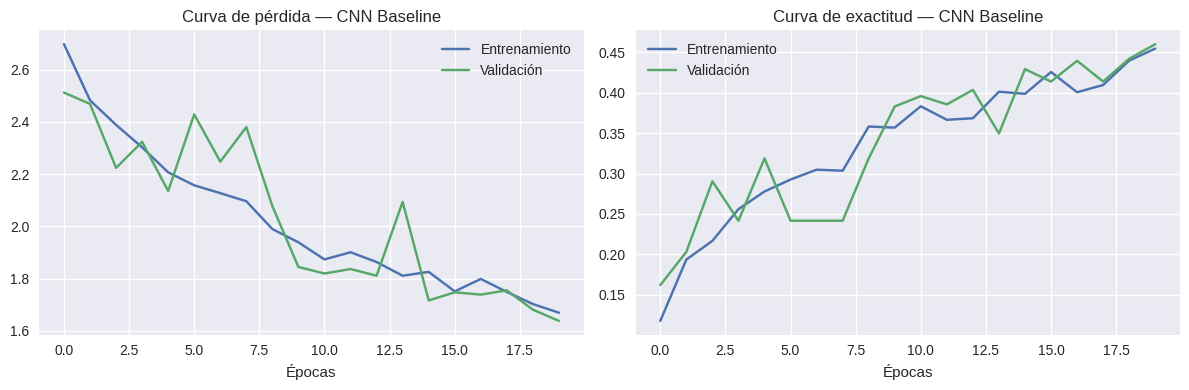

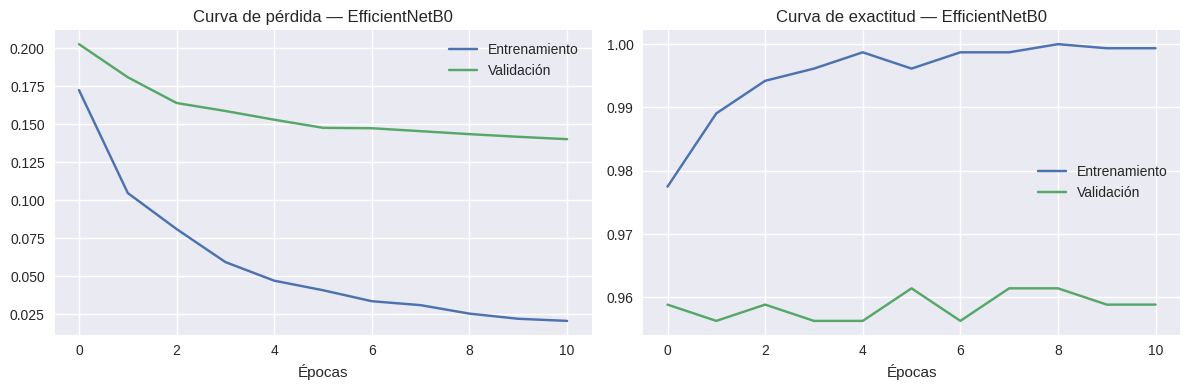

In [ ]:
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history['train_loss'], label='Entrenamiento')
    axes[0].plot(history['val_loss'],   label='Validación')
    axes[0].set_title(f'Curva de pérdida — {title}')
    axes[0].set_xlabel('Épocas'); axes[0].legend()

    axes[1].plot(history['train_acc'], label='Entrenamiento')
    axes[1].plot(history['val_acc'],   label='Validación')
    axes[1].set_title(f'Curva de exactitud — {title}')
    axes[1].set_xlabel('Épocas'); axes[1].legend()
    plt.tight_layout(); plt.show()

plot_history(history_cnn, 'CNN Baseline')
plot_history(history_eff, 'EfficientNetB0')

## 7. Evaluación — Accuracy, Balanced Accuracy, Macro-F1


Evaluacion: CNN Baseline
Accuracy: 0.4602 | Balanced Acc: 0.4547 | Macro-F1: 0.4434

Reporte de clasificacion:
              precision    recall  f1-score   support

        Bear       0.38      0.32      0.35        25
        Bird       0.57      0.63      0.60        27
         Cat       0.21      0.32      0.25        25
         Cow       0.33      0.31      0.32        26
        Deer       0.47      0.28      0.35        25
         Dog       0.18      0.42      0.25        24
     Dolphin       0.71      0.92      0.80        26
    Elephant       0.64      0.26      0.37        27
     Giraffe       0.71      0.46      0.56        26
       Horse       0.80      0.15      0.26        26
    Kangaroo       0.50      0.08      0.14        25
        Lion       0.40      0.46      0.43        26
       Panda       0.41      0.89      0.56        27
       Tiger       0.80      0.46      0.59        26
       Zebra       0.83      0.86      0.84        28

    accuracy          

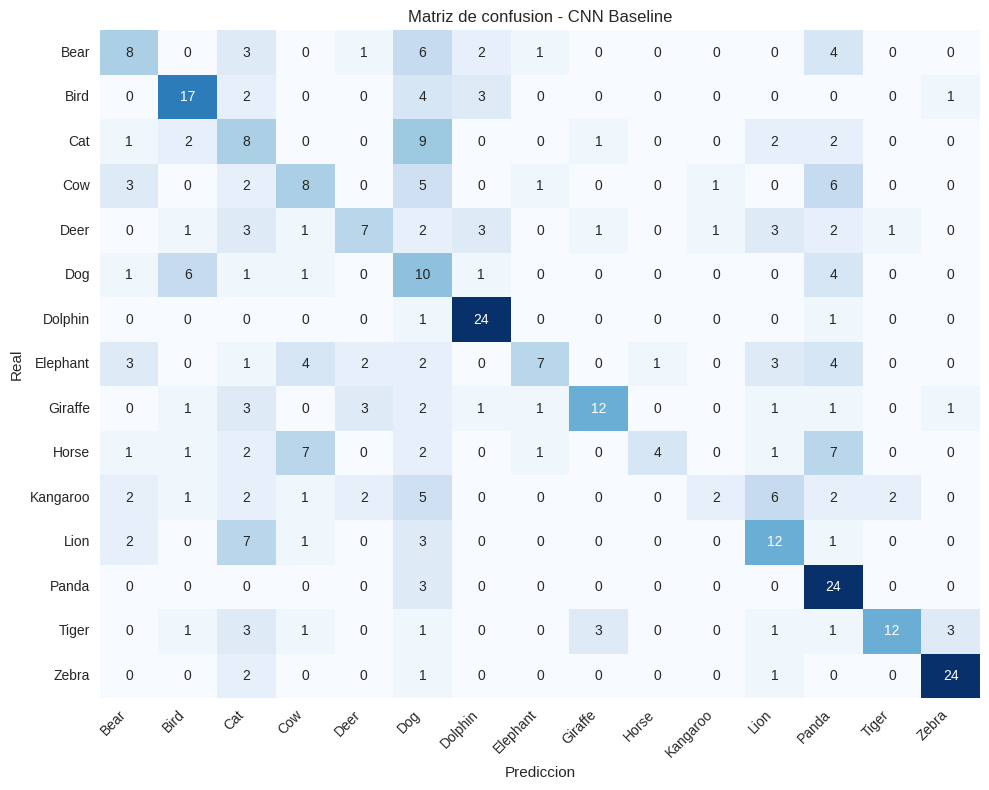


Evaluacion: EfficientNetB0
Accuracy: 0.9614 | Balanced Acc: 0.9609 | Macro-F1: 0.9610

Reporte de clasificacion:
              precision    recall  f1-score   support

        Bear       0.96      0.88      0.92        25
        Bird       0.96      0.96      0.96        27
         Cat       0.93      1.00      0.96        25
         Cow       0.88      0.88      0.88        26
        Deer       1.00      0.96      0.98        25
         Dog       0.96      0.96      0.96        24
     Dolphin       0.93      1.00      0.96        26
    Elephant       0.93      0.96      0.95        27
     Giraffe       1.00      0.96      0.98        26
       Horse       0.96      0.96      0.96        26
    Kangaroo       0.92      0.92      0.92        25
        Lion       1.00      0.96      0.98        26
       Panda       1.00      1.00      1.00        27
       Tiger       1.00      1.00      1.00        26
       Zebra       1.00      1.00      1.00        28

    accuracy        

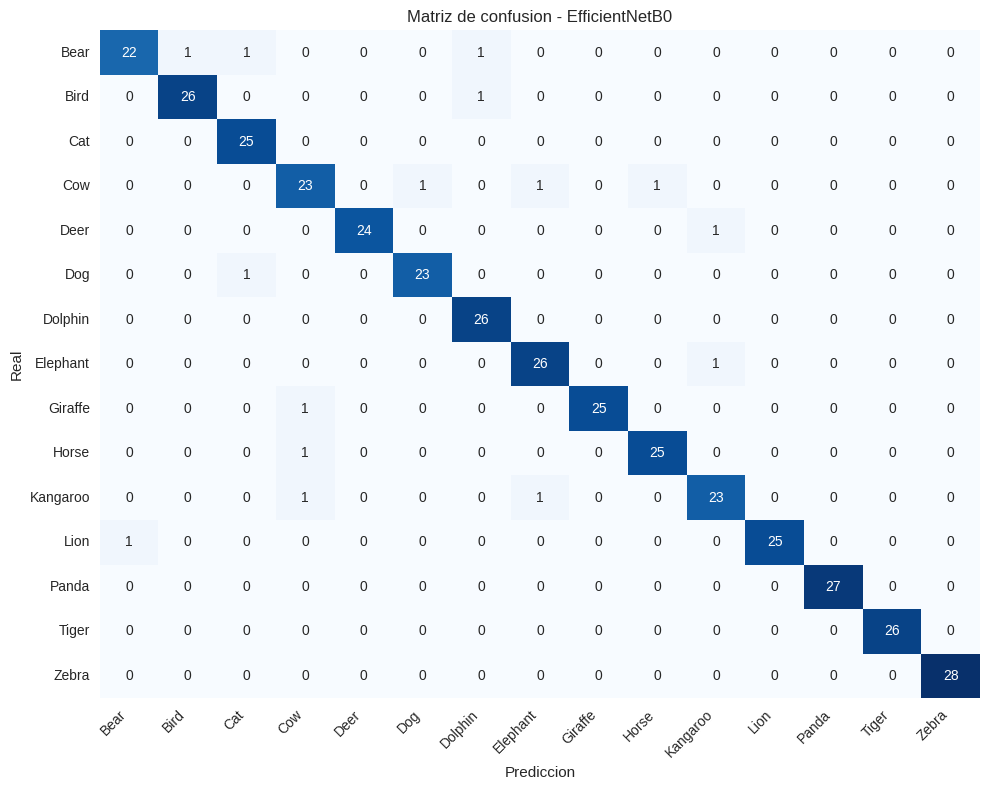

Umbral minimo para exportar: 11.7% (azar: 6.7%)


In [ ]:
def evaluate_model(model, loader, class_names, model_name):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in loader:
            outputs = model(images.to(device))
            if outputs.shape[1] != len(class_names):
                raise ValueError(f'{model_name}: salidas/clases no coinciden.')
            all_preds.extend(outputs.argmax(dim=1).cpu().numpy())
            all_labels.extend(labels.numpy())

    y_true, y_pred = np.asarray(all_labels), np.asarray(all_preds)
    acc = float((y_pred == y_true).mean())
    bal_acc = balanced_accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
    print(f'\nEvaluacion: {model_name}')
    print(f'Accuracy: {acc:.4f} | Balanced Acc: {bal_acc:.4f} | Macro-F1: {macro_f1:.4f}')
    labels = np.arange(len(class_names))
    print('\nReporte de clasificacion:')
    print(classification_report(y_true, y_pred, labels=labels,
                                target_names=class_names, zero_division=0))

    cm = confusion_matrix(y_true, y_pred, labels=labels)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Matriz de confusion - {model_name}')
    plt.xlabel('Prediccion'); plt.ylabel('Real')
    plt.xticks(rotation=45, ha='right'); plt.yticks(rotation=0)
    plt.tight_layout(); plt.show()
    return acc, bal_acc, macro_f1

acc_b, bal_b, f1_b = evaluate_model(cnnbase, val_loader, classes, 'CNN Baseline')
acc_e, bal_e, f1_e = evaluate_model(efficientnet, val_loader, classes, 'EfficientNetB0')

CHANCE_ACCURACY = 1.0 / NUM_CLASSES
MIN_ACCURACY = max(0.10, CHANCE_ACCURACY + 0.05)
print(f'Umbral minimo para exportar: {MIN_ACCURACY:.1%} (azar: {CHANCE_ACCURACY:.1%})')
for model_name, accuracy in [('CNN Baseline', acc_b), ('EfficientNetB0', acc_e)]:
    if accuracy < MIN_ACCURACY:
        print(f'AVISO: {model_name} sigue cerca del azar; no se exportara como modelo valido.')

## 8. Comparación de modelos

In [ ]:
comparison = pd.DataFrame([
    {'Modelo': 'CNN Baseline (PT)',    'Accuracy': round(acc_b, 4), 'Balanced Acc': round(bal_b, 4), 'Macro-F1': round(f1_b, 4)},
    {'Modelo': 'EfficientNetB0 (PT)', 'Accuracy': round(acc_e, 4), 'Balanced Acc': round(bal_e, 4), 'Macro-F1': round(f1_e, 4)},
]).sort_values('Accuracy', ascending=False).reset_index(drop=True)
print(comparison.to_string(index=False))

             Modelo  Accuracy  Balanced Acc  Macro-F1
EfficientNetB0 (PT)    0.9614        0.9609    0.9610
  CNN Baseline (PT)    0.4602        0.4547    0.4434


## 9. Guardar modelos y metadata
Los `state_dict` ya se guardaron durante el entrenamiento. Aquí se guarda la metadata que necesita NNApp.

In [ ]:
# Export state_dicts only when the best validation checkpoint clears the guard.
os.makedirs('models/saved', exist_ok=True)
model_paths = {
    'cnn': 'models/saved/pt_image_cnn.pt',
    'transfer': 'models/saved/pt_image_transfer.pt',
}
approved = {'cnn': acc_b >= MIN_ACCURACY, 'transfer': acc_e >= MIN_ACCURACY}
for key, model, accuracy in [('cnn', cnnbase, acc_b), ('transfer', efficientnet, acc_e)]:
    if approved[key]:
        torch.save(model.state_dict(), model_paths[key])
        print(f'Exported validated model: {model_paths[key]}')
    else:
        print(f'NOT exported: {model_paths[key]} (validation accuracy {accuracy:.1%})')
        if os.path.exists(model_paths[key]):
            print('WARNING: an older artifact is still present at this path; do not use it for this run.')

# Keep the app-compatible metadata schema and the exact model output order, even on a failed run.
meta = {'classes': classes, 'cnn_size': 128, 'transfer_size': 128}
with open('models/saved/animals_meta.json', 'w', encoding='utf-8') as f:
    json.dump(meta, f, ensure_ascii=False, indent=2)
print('Metadata saved:', meta)
comparison.to_csv('models/saved/comparacion_modelos_pt.csv', index=False)
print('Validated artifacts available:', [path for key, path in model_paths.items()
                                        if approved[key] and os.path.exists(path)])

Exported validated model: models/saved/pt_image_cnn.pt
Exported validated model: models/saved/pt_image_transfer.pt
Metadata saved: {'classes': ['Bear', 'Bird', 'Cat', 'Cow', 'Deer', 'Dog', 'Dolphin', 'Elephant', 'Giraffe', 'Horse', 'Kangaroo', 'Lion', 'Panda', 'Tiger', 'Zebra'], 'cnn_size': 128, 'transfer_size': 128}
Validated artifacts available: ['models/saved/pt_image_cnn.pt', 'models/saved/pt_image_transfer.pt']


## 10. Probar con imágenes nuevas
Se cargan los modelos desde los archivos y se clasifican imágenes que no se usaron al entrenar.

In [ ]:
def classify_pt(img_path, real_label):
    img = Image.open(img_path).convert('RGB')
    x = transform_val(img).unsqueeze(0).to(device)  # [1,3,128,128], RGB [0,1]
    with torch.no_grad():
        probs_cnn = torch.softmax(cnnbase(x), dim=1)[0].cpu().numpy()
        probs_eff = torch.softmax(efficientnet(x), dim=1)[0].cpu().numpy()
    print(f'\nImagen: {os.path.basename(img_path)} | Real: {classes[real_label]}')
    print(f'  CNN          -> {classes[int(probs_cnn.argmax())]} ({float(probs_cnn.max()):.1%})')
    print(f'  EfficientNet -> {classes[int(probs_eff.argmax())]} ({float(probs_eff.max()):.1%})')

# Una imagen de validacion por clase real distinta; no son imagenes de entrenamiento.
representatives = {}
for dataset_index in val_indices:
    img_path, label = val_base.samples[int(dataset_index)]
    representatives.setdefault(int(label), img_path)
    if len(representatives) == NUM_CLASSES:
        break
if len(representatives) < 2:
    raise RuntimeError('La validacion debe contener imagenes de al menos dos clases.')
print('Prueba final (real / predicha / confianza):')
for real_label, img_path in list(representatives.items())[:min(6, NUM_CLASSES)]:
    classify_pt(img_path, real_label)

Prueba final (real / predicha / confianza):

Imagen: Dolphin_25_2.jpg | Real: Dolphin
  CNN          -> Dolphin (14.4%)
  EfficientNet -> Dolphin (56.7%)

Imagen: Panda_19_4.jpg | Real: Panda
  CNN          -> Dog (22.8%)
  EfficientNet -> Panda (99.8%)

Imagen: Kangaroo_2_2.jpg | Real: Kangaroo
  CNN          -> Dog (25.1%)
  EfficientNet -> Kangaroo (99.7%)

Imagen: Cow_6_2.jpg | Real: Cow
  CNN          -> Cow (54.3%)
  EfficientNet -> Cow (99.8%)

Imagen: Zebra_5_2.jpg | Real: Zebra
  CNN          -> Zebra (98.8%)
  EfficientNet -> Zebra (99.7%)

Imagen: Tiger_27_1.jpg | Real: Tiger
  CNN          -> Tiger (35.3%)
  EfficientNet -> Tiger (99.7%)


## 11. Fine-tuning (opcional)
Descongelar el backbone de EfficientNet y re-entrenar con LR bajo.

In [ ]:
# Fine-tuning opcional: usa checkpoint temporal y evalua de nuevo antes de exportar.
# for param in efficientnet.base.parameters():
#     param.requires_grad = True
# history_ft = train_model(efficientnet, train_loader, val_loader,
#                          save_path='models/saved/.checkpoints/pt_image_transfer_ft_best.pt',
#                          epochs=10, lr=1e-5, patience=3)
# acc_ft, bal_ft, f1_ft = evaluate_model(efficientnet, val_loader, classes, 'EfficientNetB0 fine-tuned')
# if acc_ft >= MIN_ACCURACY:
#     torch.save(efficientnet.state_dict(), 'models/saved/pt_image_transfer.pt')
# else:
#     print('Fine-tuned model NOT exported: accuracy is near chance.')

---
### Consideraciones
- Uso exclusivamente **académico**.
- `CrossEntropyLoss` en PyTorch incluye el softmax internamente, por eso los modelos devuelven logits (sin softmax en `forward`). Al clasificar se aplica `torch.softmax` manualmente para obtener probabilidades.
- EfficientNetB0 normalmente supera la CNN con pocos datos porque ya aprendió a reconocer formas con ImageNet.
- Los pesos quedan en `models/saved/`; cópialos a NNApp para usar la app.